# Yi-Ning Li
# DSCI552 HW 5

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
from sklearn.tree import _tree

## 1. Decision Trees as Interpretable Models

### a. Download data

In [2]:
columns=['Temperature', 'Nausea', 'Lumbar_pain', 'Urine_pushing', 'Micturition_pains', 'Burning_urethra', 'Inflammation', 'Nephritis']

df=pd.read_csv('../data/diagnosis.data', header=None, sep=r'\s+', names=columns, decimal=',', encoding='utf-16')

print(df.shape)
display(df.head())

(120, 8)


,Temperature,Nausea,Lumbar_pain,Urine_pushing,Micturition_pains,Burning_urethra,Inflammation,Nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### b. decision tree

X shape:  (120, 6)
y shape:  (120, 2)
Tree depth:  4
Numbe of leaves:  6


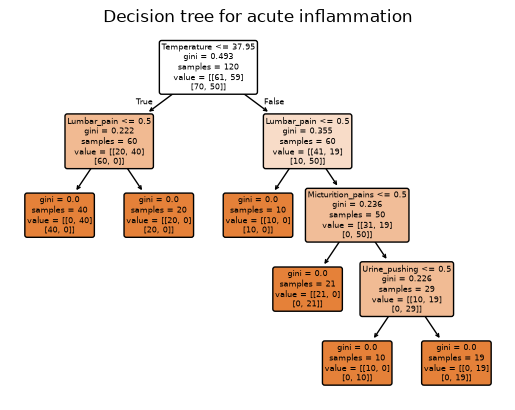

In [3]:
X=df.iloc[:, :6].replace({'yes': 1, 'no': 0}).astype(float)
y=df.iloc[:, 6:].replace({'yes': 1, 'no': 0}).astype(int)

print('X shape: ', X.shape)
print('y shape: ', y.shape)

tree=DecisionTreeClassifier(random_state=1)
tree.fit(X, y)

print('Tree depth: ', tree.get_depth())
print('Numbe of leaves: ', tree.get_n_leaves())

plt.figure()
plot_tree(tree, feature_names=X.columns, filled=True, rounded=True)
plt.title('Decision tree for acute inflammation')
plt.show()

### c. If-then rules

In [4]:
def extractRules(model, featureNames, targetNames):
    t=model.tree_

    def traverse(node, conditions):
        if t.feature[node]==_tree.TREE_UNDEFINED:
            prediction=model.classes_
            values=t.value[node]

            outcomes={
                name: classes[values[i].argmax()]
                for i, (name, classes) in enumerate(zip(targetNames, prediction))
            }

            print('IF ' + ' AND '.join(conditions))
            print('THEN ' + ', '.join(f'{name}={value}' for name, value in outcomes.items()))
            print()
            return
        feature=featureNames[t.feature[node]]
        threshold=t.threshold[node]

        traverse(t.children_left[node], conditions + [f'{feature} <= {threshold:.2f}'])
        traverse(t.children_right[node], conditions + [f'{feature} > {threshold:.2f}'])
    traverse(0, [])
extractRules(tree, list(X.columns), list(y.columns))

IF Temperature <= 37.95 AND Lumbar_pain <= 0.50
THEN Inflammation=1, Nephritis=0

IF Temperature <= 37.95 AND Lumbar_pain > 0.50
THEN Inflammation=0, Nephritis=0

IF Temperature > 37.95 AND Lumbar_pain <= 0.50
THEN Inflammation=0, Nephritis=0

IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Micturition_pains <= 0.50
THEN Inflammation=0, Nephritis=1

IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Micturition_pains > 0.50 AND Urine_pushing <= 0.50
THEN Inflammation=0, Nephritis=1

IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Micturition_pains > 0.50 AND Urine_pushing > 0.50
THEN Inflammation=1, Nephritis=1



### d. cost-complexity pruning

In [5]:
path = tree.cost_complexity_pruning_path(X, y)
alphas = path.ccp_alphas
print('CCP alphas: ', alphas)

CCP alphas:  [0.         0.04908333 0.07947222 0.11111111 0.20423611]


In [6]:
results=[]

for alpha in alphas:
    prunedTree=DecisionTreeClassifier(random_state=1, ccp_alpha=alpha)
    prunedTree.fit(X, y)
    results.append({
        'alpha': alpha,
        'depth': prunedTree.get_depth(),
        'leaves': prunedTree.get_n_leaves(),
        'accuracy': prunedTree.score(X, y)
    })

resultsDF=pd.DataFrame(results)
display(resultsDF)

,alpha,depth,leaves,accuracy
0,0.000000,4,6,1.000000
1,0.049083,2,4,0.841667
2,0.079472,2,3,0.758333
3,0.111111,1,2,0.591667
4,0.204236,0,1,0.250000


Select alpha=0.049083 for its high accuracy and relatively fewer leaves. We are looking for a tree with fewer leaves and higher accuracy. Alpha=0 is the original tree without pruning. alpha=0.079472 has a lower accuracy of 0.758 despite having 1 less leaf. Alpha=0.111 and 0.204 have even lower accuracies despite having fewer leaves. 4 Leaves is still relatively small and easy to interpret, so we select alpha=0.049083 for its good interpretability and high accuracy. 

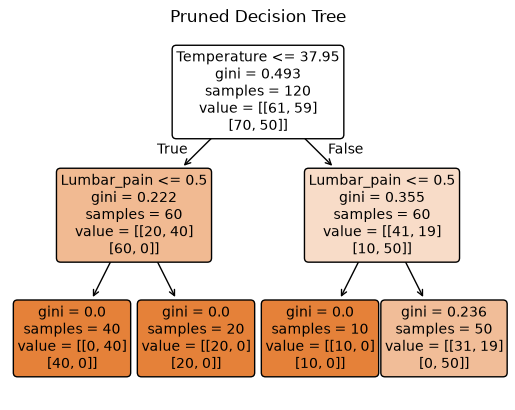

IF Temperature <= 37.95 AND Lumbar_pain <= 0.50
THEN Inflammation=1, Nephritis=0

IF Temperature <= 37.95 AND Lumbar_pain > 0.50
THEN Inflammation=0, Nephritis=0

IF Temperature > 37.95 AND Lumbar_pain <= 0.50
THEN Inflammation=0, Nephritis=0

IF Temperature > 37.95 AND Lumbar_pain > 0.50
THEN Inflammation=0, Nephritis=1



In [7]:
bestAlpha=alphas[1]
prunedTree=DecisionTreeClassifier(random_state=1, ccp_alpha=bestAlpha)
prunedTree.fit(X, y)

plt.figure()
plot_tree(
    prunedTree,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Pruned Decision Tree')
plt.show()

extractRules(prunedTree, list(X.columns), list(y.columns))

## 2. The LASSO and Boosting for Regression

### a. download data

In [8]:
crimeDF=pd.read_csv('../data/communities.data', header=None, na_values='?')
print('Dataset shape: ', crimeDF.shape)
display(crimeDF.head())

Dataset shape:  (1994, 128)


,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [10]:
trainDF = crimeDF.iloc[:1495]
testDF = crimeDF.iloc[1495:]

print('Training shape: ', trainDF.shape)
print('Testing shape: ', testDF.shape)

Training shape:  (1495, 128)
Testing shape:  (499, 128)
